Pobieranie grafu dla: Gorczański Park Narodowy, Poland...
Pobrano graf: 138 węzłów, 342 krawędzi.


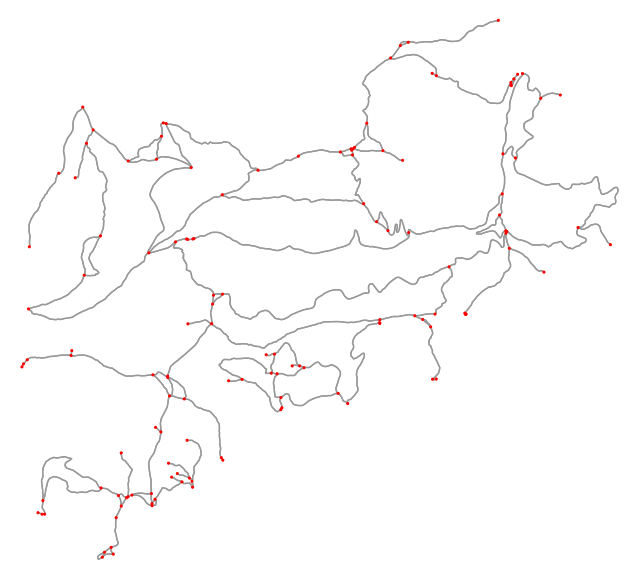

In [1]:
import osmnx as ox
import matplotlib.pyplot as plt

# 1. Konfiguracja OSMnx (logi w konsoli i cacheowanie zapytań)
ox.settings.log_console = True
ox.settings.use_cache = True
# Zwiększenie czasu oczekiwania do 3 minut (180 sekund)
ox.settings.timeout = 180
# 2. Zdefiniowanie obszaru
# Możesz użyć nazwy parku, miasta lub konkretnego szczytu
obszar = "Gorczański Park Narodowy, Poland"

# 3. Filtr pobierania (Kluczowy krok dla GOPR)
# Pobieramy: szlaki (path), drogi leśne/gruntowe (track), ścieżki (footway)
# oraz drogi nieutwardzone/lokalne (unclassified)
filtr_szlakow = '["highway"~"path|track|footway|unclassified"]'

print(f"Pobieranie grafu dla: {obszar}...")

# 4. Pobranie grafu przestrzennego
G = ox.graph_from_place(
    obszar,
    custom_filter=filtr_szlakow,
    simplify=True # Upraszcza graf matematyczny (łączy proste odcinki)
)

print(f"Pobrano graf: {len(G.nodes)} węzłów, {len(G.edges)} krawędzi.")

fig, ax = ox.plot_graph(
    G,
    node_size=5,
    node_color="red",
    edge_color="#999999",
    edge_linewidth=1,
    bgcolor="white"
)

In [2]:
# Konwersja grafu do tabel wektorowych (GeoDataFrames)
wezly, krawedzie = ox.graph_to_gdfs(G)

# Wyświetlenie pierwszych 5 krawędzi z ich typem i długością w metrach
display(krawedzie[['highway', 'length', 'geometry']].head())


highway       length  \
u         v          key                               
431066653 1211056170 0            track   335.566733   
          3024142464 0            track   612.230065   
          930011743  0    [track, path]  1805.609394   
929996381 6037513980 0             path  1320.269910   
          1195992896 0            track   408.335851   

                                                                   geometry  
u         v          key                                                     
431066653 1211056170 0    LINESTRING (20.21898 49.56712, 20.21907 49.566...  
          3024142464 0    LINESTRING (20.21898 49.56712, 20.21924 49.567...  
          930011743  0    LINESTRING (20.21898 49.56712, 20.21871 49.567...  
929996381 6037513980 0    LINESTRING (20.1465 49.54276, 20.14543 49.5427...  
          1195992896 0    LINESTRING (20.1465 49.54276, 20.14676 49.5426...